# Clasificación de textos en esperanto: física, biología y química

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danielaagonzalezz/cienciaNLP/blob/main/notebooks/clasificacion_esperanto.ipynb)

**Minería de Textos · 4º INF-A · CUNEF · 2026/2027**

**Equipo:** Daniela González ([@danielaagonzalezz](https://github.com/danielaagonzalezz)) · Olivia ([@Olivia029](https://github.com/Olivia029))

**Repositorio:** https://github.com/danielaagonzalezz/cienciaNLP

---

Este cuaderno es la **Fase 3** de la práctica. Usa lo que hicimos en las dos primeras, que está en el repositorio:

1. **Dataset** (`dataset/dataset.csv`): párrafos de la Wikipedia en esperanto etiquetados como `fiziko`, `biologio` o
   `kemio`. Lo genera el script `scripts/build_dataset.py`.
2. **Librería `ciencianlp`**: tokenizador, lematizador, POS-tagger y stop-words, basada en reglas y hecha desde cero.

Con ellos el cuaderno **vectoriza el corpus, entrena un clasificador, lo evalúa y clasifica páginas web reales**.

Hemos elegido física, biología y química porque son **temáticas cercanas**: comparten vocabulario científico
(*energio*, *molekulo*, *ĉelo*, *atomo*...), así que separarlas no es trivial.

**Independencia de temática:** el cuaderno no tiene las clases escritas en ningún sitio, las lee del dataset. Basta
con cambiar `URL_DATASET` (y la lista de páginas web `PAGINAS`) para reentrenarlo y evaluarlo con el dataset de otro
equipo que cumpla el contrato de datos.

## Índice

0. Configuración
1. Dataset: descarga y comprobación del contrato de datos
2. Procesado con `ciencianlp`
3. Exploración del dataset
4. Modelo de clasificación
5. Clasificación de páginas web
6. Conclusiones

El cuaderno se ejecuta de principio a fin con **Entorno de ejecución → Ejecutar todas**, sin GPU y en menos de un
minuto.

## 0. Configuración

Todos los parámetros están en esta celda, para que el cuaderno se ejecute sin preguntar nada al usuario.

- `URL_DATASET`: dataset que se usa. Por defecto, el nuestro; se puede poner el de otro equipo.
- `URL_DATASET_RESPALDO`: copia del mismo fichero en otro servidor, por si el primero no responde.
- `SEMILLA`: se fija para que los resultados sean reproducibles.

In [1]:
REPO = "danielaagonzalezz/cienciaNLP"
RAMA = "main"  # rama de la que se instala la librería y se lee el dataset

URL_DATASET = f"https://raw.githubusercontent.com/{REPO}/{RAMA}/dataset/dataset.csv"
URL_DATASET_RESPALDO = f"https://cdn.jsdelivr.net/gh/{REPO}@{RAMA}/dataset/dataset.csv"  # None si no hay copia

SEMILLA = 42

### Instalación

En Colab ya vienen `pandas`, `scikit-learn`, `matplotlib`, `requests` y `beautifulsoup4`. Solo falta nuestra
librería, que se instala con `pip` directamente desde el repositorio de GitHub.

In [ ]:
!pip install -q git+https://github.com/danielaagonzalezz/cienciaNLP.git

In [3]:
import math
import random
import re
from collections import Counter

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import sklearn

import ciencianlp
from ciencianlp import nlp

random.seed(SEMILLA)
np.random.seed(SEMILLA)
pd.set_option("display.max_colwidth", 220)

# Versiones usadas, para poder reproducir los resultados
for libreria in (ciencianlp, pd, np, sklearn, matplotlib, requests):
    print(f"{libreria.__name__:<12} {libreria.__version__}")

ciencianlp   0.1.0
pandas       3.1.1
numpy        2.5.4
sklearn      1.9.1
matplotlib   3.11.2
requests     2.34.2


## 1. Dataset

### 1.1 Descarga

El dataset se descarga automáticamente del repositorio de GitHub. Para que el cuaderno no falle si GitHub no responde,
si la primera URL falla se prueba la copia del CDN jsDelivr, que sirve el mismo fichero del mismo repositorio.

In [4]:
def descargar_dataset(*urls):
    """Lee el CSV de la primera URL que responda. Si ninguna responde, lanza un error claro."""
    for url in urls:
        if url is None:
            continue
        try:
            datos = pd.read_csv(url, sep=";", encoding="utf-8")
            print("Dataset leído de", url)
            return datos
        except Exception as error:  # sin red, 404, fichero corrupto...
            print("No se pudo leer", url, "->", error)
    raise RuntimeError("No se pudo descargar el dataset de ninguna fuente")


df = descargar_dataset(URL_DATASET, URL_DATASET_RESPALDO)
CLASES = sorted(df["class"].unique())  # las clases salen del dataset, no se escriben a mano
print("Clases:", CLASES)
df.head()

Dataset leído de https://raw.githubusercontent.com/danielaagonzalezz/cienciaNLP/main/dataset/dataset.csv
Clases: ['biologio', 'fiziko', 'kemio']


,text,class
0,Bruŝirmiloj antaŭ ĉio estas uzataj por redukti la bruon de vojtrafiko aŭ reltrafiko. Ekzistas tiel nomataj reflektaj kaj absorbaj bruŝirmiloj. Ĉe reflektaj bruŝirmiloj oni parolas pri reflektado de la bruo. La bruabs...,fiziko
1,La funkciado de la ŝirmilo ankaŭ dependas de la amplekso de la brufonto. Tial oni bezonas laŭlonge de larĝa aŭtovojo ofte pli altan bruŝirmilon ol laŭlonge relative mallarĝa fervojo. La efiko estas plifortigita ĉar l...,fiziko
2,"sistemon de orbitantaj sunpovaj satelitoj komplete ĉirkaŭantaj stelon aŭ sunon. Tiu strukturo nomiĝas la Dajsonsfero, kiu kaptus plejparton aŭ la tuton da la energia produktokvanto de la stelo. Pri tiu koncepto, sinj...",fiziko
3,"Ekzistas aliaj variaĵoj, tielnomataj Dajsonstrukturoj. Solida ŝelo ĉirkaŭ stelo estas la Dajsonŝelo. La Dajsonringo estas orbitanta ringo ĉirkaŭ stelo ĉe la vivebla zono, ekzemple de nia Suno ĉe radiuso de 1 AU. En l...",fiziko
4,"Ĉiu lando partoprenanta en la konkurso sendas delegacion de kvin studentoj kaj kutime ankaŭ du kunuloj-akompanantoj, kaj povas sendi observantojn kune kun la delegacio. La delegacio estas elektita per preparaj konkur...",fiziko


### 1.2 Comprobación del contrato de datos

El enunciado fija un contrato para el dataset. Lo comprobamos con `assert`, de forma que si algo no se cumple el
cuaderno se para y avisa:

- dos columnas con cabecera `text;class`,
- ningún párrafo vacío ni con el carácter `;`,
- al menos 3 clases,
- párrafos limpios: sin HTML, enlaces ni referencias del tipo `[1]`.

In [5]:
assert list(df.columns) == ["text", "class"], "Las columnas deben ser text;class"
assert df["text"].notna().all() and (df["text"].str.strip() != "").all(), "Hay párrafos vacíos"
assert not df["text"].str.contains(";").any(), "Algún párrafo contiene ';'"
assert df["class"].nunique() >= 3, "Hacen falta al menos 3 clases"

restos = r"<[a-z/][^>]*>|https?://|www\.|\[\d+\]"  # HTML, enlaces y referencias
assert not df["text"].str.contains(restos).any(), "Quedan restos de HTML, enlaces o referencias"

print(f"Contrato cumplido: {len(df)} párrafos, {df['class'].nunique()} clases")
df["class"].value_counts().rename("párrafos").to_frame()

Contrato cumplido: 1123 párrafos, 3 clases


,párrafos
class,
biologio,391
fiziko,375
kemio,357


## 2. Procesado con `ciencianlp`

Nuestra librería tiene una API parecida a la de spaCy: `nlp(texto)` devuelve un `Doc`, que se recorre token a token.
Cada `Token` trae su lema (`lemma_`), su etiqueta gramatical (`pos_`) y si es una stop-word (`is_stop`).

In [6]:
ejemplo = nlp("La elektronoj de la atomo moviĝas ĉirkaŭ la kerno.")
pd.DataFrame([{"text": t.text, "lemma_": t.lemma_, "pos_": t.pos_, "is_stop": t.is_stop, "is_alpha": t.is_alpha}
              for t in ejemplo])

,text,lemma_,pos_,is_stop,is_alpha
0,La,la,DET,True,True
1,elektronoj,elektrono,NOUN,False,True
2,de,de,ADP,True,True
3,la,la,DET,True,True
4,atomo,atomo,NOUN,False,True
5,moviĝas,moviĝi,VERB,False,True
6,ĉirkaŭ,ĉirkaŭ,ADP,True,True
7,la,la,DET,True,True
8,kerno,kerno,NOUN,False,True
9,.,.,PUNCT,False,False


### 2.1 Palabras de cada párrafo

Igual que en el ejercicio 06 de clase, de cada párrafo nos quedamos con los **lemas** de las palabras que aportan
información sobre el tema:

- solo palabras (`is_alpha`): fuera signos y números;
- sin **stop-words** (*la*, *de*, *kaj*, *estas*...), que aparecen igual en las tres clases;
- solo las categorías gramaticales de `POS_TAGS`, según **nuestro POS-tagger**: sustantivos, adjetivos, verbos y `X`
  (nombres propios y siglas). Los adverbios y el resto de palabras gramaticales no ayudan a distinguir el tema;
- en forma de **lema**, para que *ĉelo*, *ĉeloj*, *ĉelon* y *ĉelojn* cuenten como la misma palabra.

In [7]:
POS_TAGS = {"NOUN", "ADJ", "VERB", "X"}


def words_of(doc):
    """Los lemas de las palabras de un Doc que pasan los filtros."""
    words = []
    for token in doc:
        if token.is_alpha and not token.is_stop and token.pos_ in POS_TAGS:
            words.append(token.lemma_)
    return words


docs = [nlp(texto) for texto in df["text"]]
df["lemas"] = [words_of(doc) for doc in docs]
df[["text", "lemas"]].head(3)

,text,lemas
0,Bruŝirmiloj antaŭ ĉio estas uzataj por redukti la bruon de vojtrafiko aŭ reltrafiko. Ekzistas tiel nomataj reflektaj kaj absorbaj bruŝirmiloj. Ĉe reflektaj bruŝirmiloj oni parolas pri reflektado de la bruo. La bruabs...,"[bruŝirmilo, uzata, redukti, bruo, vojtrafiko, reltrafiko, ekzisti, nomata, reflekta, absorba, bruŝirmilo, reflekta, bruŝirmilo, paroli, reflektado, bruo, bruabsorba, ŝirmilo, alta, kvalito, bruo, ŝirmilo, absorbi, m..."
1,La funkciado de la ŝirmilo ankaŭ dependas de la amplekso de la brufonto. Tial oni bezonas laŭlonge de larĝa aŭtovojo ofte pli altan bruŝirmilon ol laŭlonge relative mallarĝa fervojo. La efiko estas plifortigita ĉar l...,"[funkciado, ŝirmilo, dependi, amplekso, brufonto, bezoni, larĝa, aŭtovojo, alta, bruŝirmilo, mallarĝa, fervojo, efiko, plifortigita, aŭtovojo, rifuĝa, leno]"
2,"sistemon de orbitantaj sunpovaj satelitoj komplete ĉirkaŭantaj stelon aŭ sunon. Tiu strukturo nomiĝas la Dajsonsfero, kiu kaptus plejparton aŭ la tuton da la energia produktokvanto de la stelo. Pri tiu koncepto, sinj...","[sistemo, orbitanta, sunpova, satelito, ĉirkaŭanta, stelo, suno, strukturo, nomiĝi, dajsonsfero, kapti, plejparto, tuto, energia, produktokvanto, stelo, koncepto, sinjoro, dyso, influi, verko, stelfaranto, olaf, stap..."


In [8]:
# Cuánto reduce el vocabulario el lematizador
formas = set()
lemas = set()
for doc in docs:
    for token in doc:
        if token.is_alpha:
            formas.add(token.text.lower())
            lemas.add(token.lemma_)
print(f"Vocabulario: {len(formas)} formas distintas -> {len(lemas)} lemas "
      f"({1 - len(lemas) / len(formas):.0%} menos gracias al lematizador)")

Vocabulario: 14578 formas distintas -> 10999 lemas (25% menos gracias al lematizador)


### 2.2 Etiquetas gramaticales del corpus

Porcentaje de tokens de cada categoría gramatical en cada clase. La fila `X` son las palabras que el etiquetador no
sabe clasificar (nombres propios sin terminación esperanta, siglas, fórmulas...); sirve para ver hasta dónde llegan
las reglas.

In [9]:
filas = []
for doc, clase in zip(docs, df["class"]):
    for token in doc:
        filas.append({"class": clase, "pos": token.pos_})
etiquetas = pd.DataFrame(filas)

tabla_pos = pd.crosstab(etiquetas["pos"], etiquetas["class"], normalize="columns") * 100
tabla_pos.round(1).sort_values(CLASES[0], ascending=False)

class,biologio,fiziko,kemio
pos,,,
NOUN,23.2,22.6,22.7
PUNCT,15.3,15.1,15.8
ADP,12.4,11.9,12.8
ADJ,12.2,12.8,11.8
VERB,8.8,9.6,8.7
DET,8.4,8.6,8.2
ADV,6.7,6.6,6.3
CCONJ,3.8,3.4,3.4
X,3.5,3.1,3.6


## 3. Exploración del dataset

### 3.1 Tamaño de las clases y longitud de los párrafos

Comprobamos que las clases están equilibradas (si una tuviera muchos más párrafos, el modelo tendería a predecirla) y
cómo de largos son los párrafos.

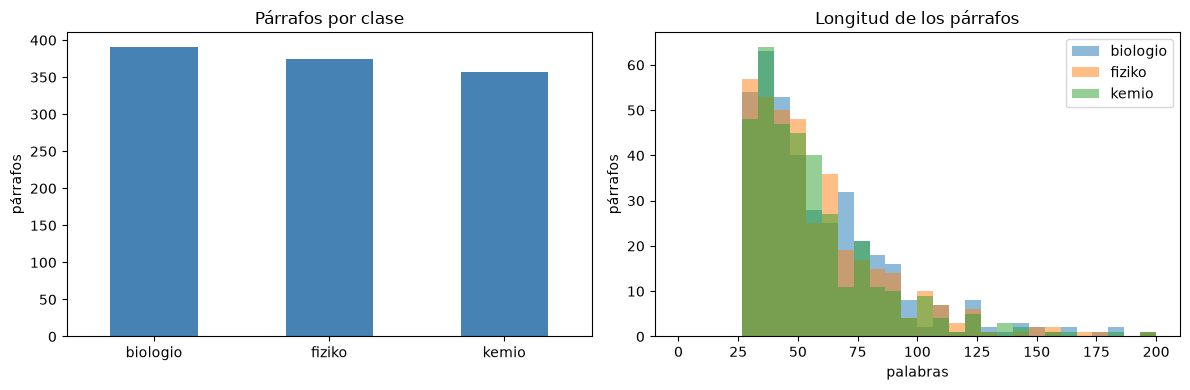

,mean,50%,min,max
class,,,,
biologio,60.0,51.0,30.0,198.0
fiziko,59.0,51.0,30.0,234.0
kemio,57.0,48.0,30.0,199.0


In [10]:
df["n_palabras"] = df["text"].str.split().str.len()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
df["class"].value_counts().reindex(CLASES).plot.bar(ax=ax1, color="steelblue", rot=0)
ax1.set(title="Párrafos por clase", xlabel="", ylabel="párrafos")
for clase in CLASES:
    ax2.hist(df.loc[df["class"] == clase, "n_palabras"], bins=30, range=(0, 200), alpha=0.5, label=clase)
ax2.set(title="Longitud de los párrafos", xlabel="palabras", ylabel="párrafos")
ax2.legend()
plt.tight_layout()
plt.show()

df.groupby("class")["n_palabras"].describe()[["mean", "50%", "min", "max"]].round(0)

### 3.2 Lemas más frecuentes por clase

Los 15 lemas más frecuentes de cada clase. Contamos en cuántos párrafos aparece cada lema, no cuántas veces, para que
un párrafo que repite mucho una palabra no pese de más.

In [11]:
frecuentes = {}
for clase in CLASES:
    contador = Counter()
    for lemas_parrafo in df.loc[df["class"] == clase, "lemas"]:
        contador.update(set(lemas_parrafo))
    frecuentes[clase] = contador

pd.DataFrame({clase: [f"{lema} ({n})" for lema, n in frecuentes[clase].most_common(15)] for clase in CLASES})

,biologio,fiziko,kemio
0,povi (83),povi (110),povi (81)
1,alia (75),alia (67),kemia (55)
2,parto (54),havi (59),atomo (54)
3,specio (46),forto (50),substanco (51)
4,havi (43),elektra (48),elemento (50)
5,kelka (40),fiziko (42),alia (47)
6,homo (38),energio (41),havi (42)
7,granda (36),fizika (35),molekulo (40)
8,homa (33),granda (34),ĥemia (36)
9,sistemo (31),kampo (32),elektrono (33)


In [12]:
top = [{lema for lema, _ in frecuentes[clase].most_common(50)} for clase in CLASES]
comunes = set.intersection(*top)
print(f"De los 50 lemas más frecuentes de cada clase, {len(comunes)} son comunes a todas:")
print(", ".join(sorted(comunes)))

De los 50 lemas más frecuentes de cada clase, 9 son comunes a todas:
a, alia, granda, havi, multa, povi, sistemo, uzata, uzi


Que muchos de los lemas más frecuentes sean comunes a todas las clases confirma que las temáticas son
**cercanas**: comparten el vocabulario general de la ciencia. Por eso usaremos TF-IDF, que da menos peso a las
palabras que aparecen en todas partes.

## 4. Modelo de clasificación

### 4.1 Partición entrenamiento / test

Separamos un 20 % del dataset como **test**. No se usa hasta la evaluación final, así la nota que obtenga el modelo en
test es una estimación honesta de cómo funcionará con textos nuevos. La partición es **estratificada** (cada clase
tiene la misma proporción en train y en test) y usa la semilla fija.

In [13]:
from sklearn.model_selection import train_test_split

train, test = train_test_split(df, test_size=0.2, stratify=df["class"], random_state=SEMILLA)
print(f"Entrenamiento: {len(train)} párrafos · Test: {len(test)} párrafos")
pd.DataFrame({"train": train["class"].value_counts(), "test": test["class"].value_counts()})

Entrenamiento: 898 párrafos · Test: 225 párrafos


,train,test
class,,
biologio,313,78
fiziko,300,75
kemio,285,72


### 4.2 Vectorización TF-IDF

Pasamos cada párrafo a una fila de números (representación **tabular**) con TF-IDF, igual que en el ejercicio 06:

$$
TF(t, d) = \frac{f(t, d)}{|d|}
\qquad
IDF(t) = \log\frac{N + 1}{n_t + 1} + 1
\qquad
\vec{d}[t] = TF(t, d) \cdot IDF(t)
$$

- $f(t, d)$: veces que aparece el lema $t$ en el párrafo $d$; $|d|$: lemas de $d$ que están en la bolsa de palabras.
- $N$: número de párrafos de entrenamiento; $n_t$: párrafos de entrenamiento que contienen $t$.
- Al final cada vector se **normaliza** (longitud 1), para que los párrafos largos no tengan valores más grandes.

Así, un lema que sale en casi todos los párrafos (*povi*, *havi*...) pesa poco, y uno específico (*ĉelo*,
*elektrono*...) pesa mucho.

La **bolsa de palabras** son los lemas que aparecen más de `MIN_COUNT` veces en entrenamiento: los que salen una
sola vez no ayudan a generalizar y suelen ser nombres propios o erratas. Tanto la bolsa como el IDF se calculan **solo
con los párrafos de entrenamiento**; el test se vectoriza con ellos, sin mirarlo antes.

In [14]:
MIN_COUNT = 2


def choose_words(listas, min_count):
    """La bolsa de palabras: los lemas que aparecen más de min_count veces."""
    counts = Counter()
    for words in listas:
        counts.update(words)
    return sorted(word for word, count in counts.items() if count > min_count)


def compute_idf(listas, words):
    """El IDF de cada lema de la bolsa: {lema: idf}."""
    N = len(listas)
    document_frequency = Counter()
    for text_words in listas:
        document_frequency.update(set(text_words))  # set: cada lema cuenta una vez por párrafo
    idf = {}
    for word in words:
        idf[word] = math.log((N + 1) / (document_frequency[word] + 1)) + 1
    return idf


def vectorize(listas, words, idf):
    """Una fila por párrafo y una columna por lema de la bolsa, con su TF-IDF normalizado."""
    rows = []
    for text_words in listas:
        text_words = [word for word in text_words if word in idf]  # solo los lemas de la bolsa
        counts = Counter(text_words)  # f(t, d)
        size = len(text_words)        # |d|
        row = {}
        for word in counts:           # el resto de columnas valen 0
            row[word] = counts[word] / size * idf[word]  # TF(t, d) * IDF(t)
        norm = math.sqrt(sum(value ** 2 for value in row.values()))
        for word in row:
            row[word] /= norm
        rows.append(row)
    return pd.DataFrame(rows, columns=words).fillna(0.0)


WORDS = choose_words(train["lemas"], MIN_COUNT)
IDF = compute_idf(train["lemas"], WORDS)
X_train = vectorize(train["lemas"], WORDS, IDF)
X_test = vectorize(test["lemas"], WORDS, IDF)
y_train = train["class"].to_numpy()
y_test = test["class"].to_numpy()

print(f"Bolsa de palabras: {len(WORDS)} lemas (más de {MIN_COUNT} veces; {', '.join(sorted(POS_TAGS))})")
print(f"X_train: {X_train.shape} · X_test: {X_test.shape}")
X_train.iloc[:5, :12]

Bolsa de palabras: 2196 lemas (más de 2 veces; ADJ, NOUN, VERB, X)
X_train: (898, 2196) · X_test: (225, 2196)


,a,abdomena,abraham,absoluta,absorbo,abundo,acida,acido,adopti,aerfluo,aero,aerodinamiko
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


### 4.3 Comparación de modelos

Probamos los cuatro modelos vistos en clase con **validación cruzada de 5 particiones** sobre el conjunto de
entrenamiento (el test sigue sin tocarse). Medimos el **F1 macro**: la media del F1 de cada clase, que trata igual a
todas las clases.

Los parámetros de cada modelo los elegimos tras probar varios valores a mano, como en el ejercicio 06.

In [15]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score
from sklearn.naive_bayes import MultinomialNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier

MODELOS = {
    "KNN (k = 10, distancia coseno)": KNeighborsClassifier(n_neighbors=10, metric="cosine"),
    "Naive Bayes (alpha = 0.1)": MultinomialNB(alpha=0.1),
    "Regresión logística (C = 10)": LogisticRegression(C=10, max_iter=1000),
    "Árbol de decisión (profundidad 20)": DecisionTreeClassifier(max_depth=20, random_state=SEMILLA),
}

resultados_cv = {}
for nombre, modelo_cv in MODELOS.items():
    notas = cross_val_score(modelo_cv, X_train, y_train, cv=5, scoring="f1_macro")
    resultados_cv[nombre] = {"F1 macro": notas.mean(), "desviación": notas.std()}

comparacion = pd.DataFrame(resultados_cv).T.sort_values("F1 macro", ascending=False)
comparacion.round(3)

,F1 macro,desviación
Naive Bayes (alpha = 0.1),0.850,0.019
Regresión logística (C = 10),0.847,0.019
"KNN (k = 10, distancia coseno)",0.829,0.028
Árbol de decisión (profundidad 20),0.583,0.009


#### ¿Aporta algo nuestra librería?

Repetimos lo mismo con la regresión logística, pero **sin `ciencianlp`**: cada párrafo se parte en palabras con una
expresión regular, sin lematizar, sin quitar stop-words y sin filtrar por categoría gramatical.

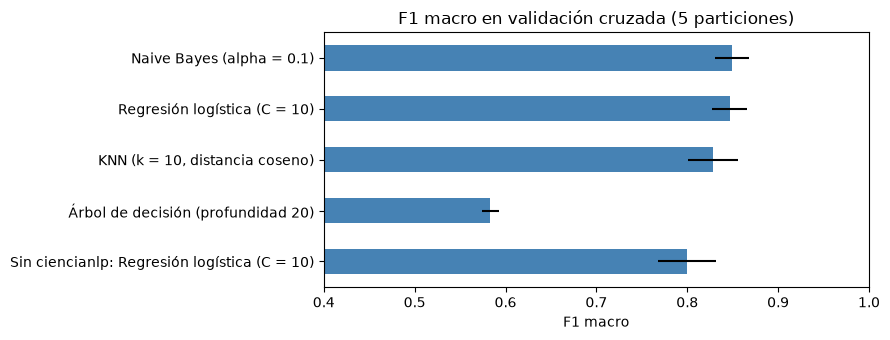

,F1 macro,desviación
Naive Bayes (alpha = 0.1),0.850,0.019
Regresión logística (C = 10),0.847,0.019
"KNN (k = 10, distancia coseno)",0.829,0.028
Árbol de decisión (profundidad 20),0.583,0.009
Sin ciencianlp: Regresión logística (C = 10),0.800,0.032


In [16]:
palabras_sin_libreria = train["text"].str.lower().str.findall(r"[^\W\d_]+")
words_sin = choose_words(palabras_sin_libreria, MIN_COUNT)
X_sin = vectorize(palabras_sin_libreria, words_sin, compute_idf(palabras_sin_libreria, words_sin))
notas_sin = cross_val_score(LogisticRegression(C=10, max_iter=1000), X_sin, y_train, cv=5, scoring="f1_macro")
comparacion.loc["Sin ciencianlp: Regresión logística (C = 10)"] = [notas_sin.mean(), notas_sin.std()]

ax = comparacion["F1 macro"].plot.barh(xerr=comparacion["desviación"], color="steelblue", figsize=(9, 3.5))
ax.set(title="F1 macro en validación cruzada (5 particiones)", xlabel="F1 macro", ylabel="", xlim=(0.4, 1))
ax.invert_yaxis()
plt.tight_layout()
plt.show()
comparacion.round(3)

**Qué vemos:**

- Naive Bayes y la regresión logística son los mejores, prácticamente empatados; KNN va un poco por detrás y el árbol
  de decisión es claramente peor: con miles de columnas casi siempre a 0, un árbol necesita muchas preguntas para
  separar las clases, mientras que los modelos lineales suman la evidencia de todas las palabras a la vez.
- **Nuestra librería sí marca la diferencia:** sin lematizar ni filtrar, la regresión logística baja varios puntos de
  F1. Lematizar junta las formas de cada palabra (*ĉelo*, *ĉelojn*...) y el filtro de stop-words y POS quita
  palabras que no indican el tema.

### 4.4 Modelo final

Nos quedamos con la **regresión logística**. Empata con Naive Bayes en F1, pero sus probabilidades son más realistas
(Naive Bayes casi siempre da 0 % o 100 %), y las necesitamos para decir la probabilidad de cada clase en las páginas
web. Además, fue el mejor modelo en el ejercicio 06.

La entrenamos con todo el conjunto de entrenamiento y la evaluamos **una sola vez** en test.

In [17]:
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, classification_report, f1_score

modelo = LogisticRegression(C=10, max_iter=1000)
modelo.fit(X_train, y_train)

pred = modelo.predict(X_test)
probas = modelo.predict_proba(X_test)

print(f"Accuracy: {accuracy_score(y_test, pred):.3f}")
print(f"F1 macro: {f1_score(y_test, pred, average='macro'):.3f}")
print()
print(classification_report(y_test, pred, digits=3))

Accuracy: 0.862
F1 macro: 0.861

              precision    recall  f1-score   support

    biologio      0.867     0.923     0.894        78
      fiziko      0.871     0.813     0.841        75
       kemio      0.847     0.847     0.847        72

    accuracy                          0.862       225
   macro avg      0.862     0.861     0.861       225
weighted avg      0.862     0.862     0.862       225



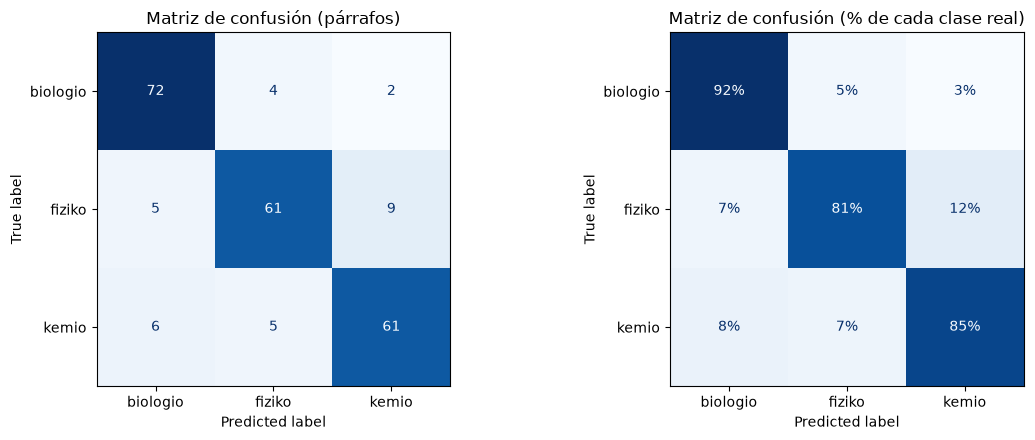

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ConfusionMatrixDisplay.from_predictions(y_test, pred, ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title("Matriz de confusión (párrafos)")
ConfusionMatrixDisplay.from_predictions(y_test, pred, ax=axes[1], cmap="Blues", colorbar=False,
                                        normalize="true", values_format=".0%")
axes[1].set_title("Matriz de confusión (% de cada clase real)")
plt.tight_layout()
plt.show()

**Qué vemos:** el resultado en test es parecido al de la validación cruzada, así que el modelo no está
sobreajustado. Los errores están repartidos entre todas las parejas de clases: no hay dos temáticas que el modelo
confunda sistemáticamente, lo que encaja con que las tres comparten vocabulario científico general.

### 4.5 Análisis del modelo

#### Lemas más influyentes

En la regresión logística cada clase tiene un coeficiente por lema: cuanto más alto, más empuja ese lema hacia la
clase.

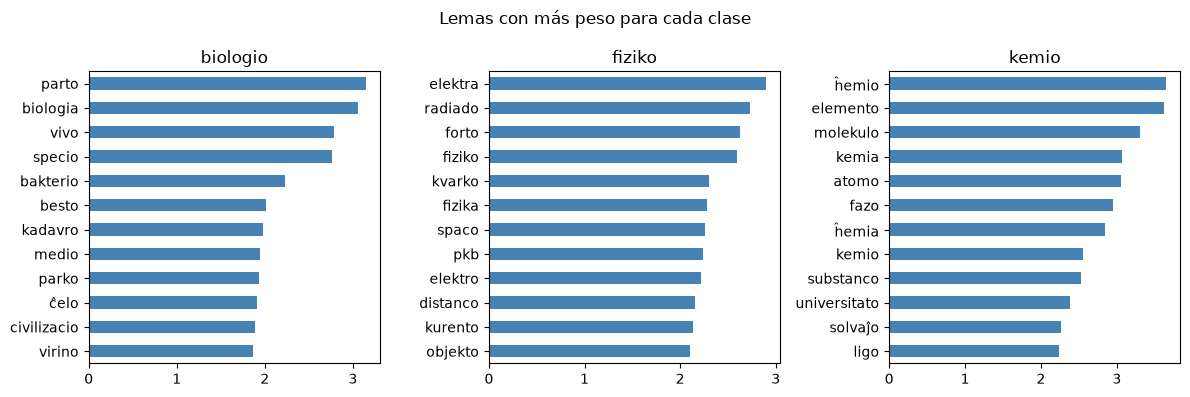

In [19]:
fig, axes = plt.subplots(1, len(modelo.classes_), figsize=(4 * len(modelo.classes_), 4))
for ax, clase, pesos in zip(axes, modelo.classes_, modelo.coef_):
    mejores = pd.Series(pesos, index=WORDS).nlargest(12).sort_values()
    mejores.plot.barh(ax=ax, color="steelblue")
    ax.set_title(clase)
plt.suptitle("Lemas con más peso para cada clase")
plt.tight_layout()
plt.show()

**Qué vemos:**

- La mayoría de los lemas son vocabulario propio de cada ciencia (*biologio*, *specio*, *bakterio*, *ĉelo* /
  *elektra*, *radiado*, *forto*, *kvarko* / *elemento*, *molekulo*, *atomo*, *substanco*), así que el modelo aprende el
  tema y no casualidades.
- Algunos lemas delatan el **ruido** del dataset: *universitato* en química o *parko* y *virino* en biología vienen
  de párrafos de biografías o temas no científicos que heredaron la etiqueta de su artículo.
- También se ve una limitación de la librería: *ĥemio* y *kemio* son la misma palabra (la grafía con *ĥ* es la
  antigua) y quedan como lemas distintos. Normalizar *ĥ* → *k* en el lematizador los juntaría.

#### Confianza del modelo

Probabilidad que da el modelo a la clase que predice, separando aciertos y errores. Un buen modelo debería
equivocarse sobre todo cuando duda.

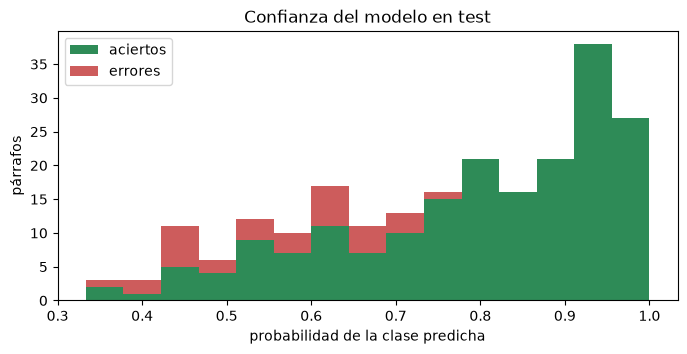

Confianza media en los aciertos: 0.80
Confianza media en los errores:  0.56


In [20]:
resultados_test = test[["text", "class"]].copy()
resultados_test["pred"] = pred
resultados_test["confianza"] = probas.max(axis=1)
resultados_test["acierto"] = resultados_test["pred"] == resultados_test["class"]
for i, clase in enumerate(modelo.classes_):
    resultados_test[f"P({clase})"] = probas[:, i].round(2)

aciertos = resultados_test[resultados_test["acierto"]]
errores = resultados_test[~resultados_test["acierto"]]

plt.figure(figsize=(8, 3.5))
plt.hist([aciertos["confianza"], errores["confianza"]], bins=15, range=(1 / len(CLASES), 1), stacked=True,
         color=["seagreen", "indianred"], label=["aciertos", "errores"])
plt.xlabel("probabilidad de la clase predicha")
plt.ylabel("párrafos")
plt.legend()
plt.title("Confianza del modelo en test")
plt.show()

print(f"Confianza media en los aciertos: {aciertos['confianza'].mean():.2f}")
print(f"Confianza media en los errores:  {errores['confianza'].mean():.2f}")

#### Ejemplos de predicciones correctas e incorrectas

In [21]:
columnas = ["class", "pred"] + [f"P({clase})" for clase in modelo.classes_] + ["text"]

print("Aciertos con más confianza:")
display(aciertos.nlargest(3, "confianza")[columnas])
print("Errores con más confianza:")
display(errores.nlargest(6, "confianza")[columnas])

Aciertos con más confianza:


,class,pred,P(biologio),P(fiziko),P(kemio),text
1095,kemio,kemio,0.00,0.0,0.99,"La perioda tabelo de ĥemiaj elementoj estas tabela prezento de ĉiuj konataj ĥemiaj elementoj. Kvankam variantoj de la tabelo ekzistis jam antaŭe, la honoro de ĝia invento estas atribuita al la rusa ĥemiisto Dmitrij M..."
683,biologio,biologio,0.99,0.0,0.00,"La supertarsa artiko estas la kunejo inter la tarsaj ostoj kaj tibio de piedfingraj aŭ hufulaj kvarpiedaj mamuloj, kiaj ĉevalo, kato, aŭ hundo. Tiu kunejo povas inkludi artikojn inter tarsaj ostoj kaj la fibulo en ke..."
480,biologio,biologio,0.99,0.0,0.01,"Evolucio estas la biologia teorio de Alfred Russel Wallace kaj Charles Darwin, kiu klarigas la evoluon de specioj per natura selektado: ""la pluvivado de la plej taŭgaj"". Iom simpligite, evolucio diras, ke specioj evo..."


Errores con más confianza:


,class,pred,P(biologio),P(fiziko),P(kemio),text
246,fiziko,kemio,0.11,0.16,0.74,"Kiun kristalan strukturon la fluido formas, dependas de la kemio de la fluido kaj la fizikaj kondiĉoj, sub kiu ĝi komencas solidiĝi, inkludantaj la median premon. Vidu la artikolon sub fazo por pli da informo. La pro..."
179,fiziko,kemio,0.03,0.24,0.73,"Gaso konsistas el rapide moviĝantaj molekuloj, kiuj kolizias inter si kaj kun la parietoj de la ujo entenanta la gason. Tio estigas premon. la averaĝa kineta energio de molekulo estas proporcia al la absoluta tempera..."
153,fiziko,biologio,0.72,0.24,0.04,"A. L. Cullen, J. Dobson, ""The Corona Breakdown of Aerials in Air at Low Pressures"". Proceedings of the Royal Society of London. Series A, Mathematical and Physical Sciences, Vol. 271, No. 1347 (February 12, 1963), pp..."
1012,kemio,fiziko,0.05,0.71,0.23,"Senkompare la plej granda kaj plej grava parto de lia laboro koncernis kemion, fizikon, elektron kaj magnetismon. Poggendorff estas konata pro sia elektrostatika motoro kiu estas analoga al la elektrostatika maŝino d..."
184,fiziko,kemio,0.02,0.29,0.69,"Ekzemple, laŭ la kvantuma teorio, se E0 estus la plej malgranda energio por interŝanĝi kun la plej malalta energinivelo de elektronoj en atomo, la aliajn energioj E por interŝanĝoj estus nur multobloj"
105,fiziko,biologio,0.68,0.25,0.07,"Estas Grundefiko la aerodinamika fenomeno kiu okazas kiam korpo, kun diferenco de premoj inter la zono kiu estas super ĝi kaj tiu kiu estas sub ĝi, estas tre proksima de la tera surfaco, kio provokas ŝanĝojn en la ae..."


**Qué vemos:** muchos de los "errores" más seguros no son fallos del modelo, sino **párrafos mal etiquetados**:
el modelo reconoce el tema real del párrafo, pero la etiqueta heredada del artículo es otra (por ejemplo, un párrafo
de genética dentro de un artículo de química). Es el **ruido** que introduce heredar la etiqueta del artículo; con el
script `scripts/medir_ruido.py` lo medimos y sale que, como mucho, un 22 % de los párrafos son posible ruido (ver README). También puede aparecer
alguna referencia bibliográfica que se coló en el dataset; es una mejora pendiente para `scripts/clean_dataset.py`.

## 5. Clasificación de páginas web

### 5.1 Clasificar un texto nuevo

Para clasificar cualquier texto se hace exactamente lo mismo que con el dataset: `ciencianlp` saca sus lemas
(`words_of`), se vectorizan con la misma bolsa de palabras e IDF del entrenamiento (`vectorize`) y el modelo da la
probabilidad de cada clase.

In [22]:
def clasificar(textos):
    """Probabilidad de cada clase para una lista de textos (una fila por texto)."""
    listas = [words_of(nlp(texto)) for texto in textos]
    X = vectorize(listas, WORDS, IDF)
    return pd.DataFrame(modelo.predict_proba(X), columns=modelo.classes_)


frases = [
    "La elektronoj moviĝas ĉirkaŭ la atomkerno pro la elektromagneta forto.",
    "La ĉeloj de la plantoj enhavas kloroplastojn kaj DNA.",
    "Kiam oni miksas acidon kun bazo, okazas kemia reakcio kaj formiĝas salo kaj akvo.",
]
probabilidades = clasificar(frases).round(3)
probabilidades["texto"] = frases
probabilidades

,biologio,fiziko,kemio,texto
0,0.047,0.773,0.181,La elektronoj moviĝas ĉirkaŭ la atomkerno pro la elektromagneta forto.
1,0.906,0.035,0.059,La ĉeloj de la plantoj enhavas kloroplastojn kaj DNA.
2,0.021,0.012,0.967,"Kiam oni miksas acidon kun bazo, okazas kemia reakcio kaj formiĝas salo kaj akvo."


### 5.2 Extracción del texto de una página web (*web scraping*)

Como en el ejercicio 08, descargamos la página con `requests` y buscamos las etiquetas con `BeautifulSoup`:

1. La zona del contenido principal: `div.mw-parser-output` en Wikipedia o, si no existe, todo el `<body>`. Así se
   evitan menús y pies de página.
2. Quitamos las referencias (`<sup>`, los `[1]`) y las tablas.
3. Cogemos los párrafos (`<p>`), quitamos el `;` y los espacios de más, y descartamos los que tienen menos de
   `MIN_PALABRAS_WEB` palabras (pies de foto, fórmulas sueltas...).

**Robustez:** todo va dentro de un `try`/`except`. Si la web no responde, no existe o devuelve un error, la función
avisa y devuelve una lista vacía, y el cuaderno sigue con las demás páginas.

In [23]:
from bs4 import BeautifulSoup

MIN_PALABRAS_WEB = 20
CABECERAS = {"User-Agent": f"ciencianlp-practica/1.0 (https://github.com/{REPO}; proyecto educativo)"}


def extraer_parrafos(url):
    """Párrafos limpios de una página web. Si algo falla, avisa y devuelve una lista vacía."""
    try:
        response = requests.get(url, headers=CABECERAS, timeout=20)
        response.raise_for_status()  # error si la página devuelve 404, 500...
    except Exception as error:
        print(f"No se pudo leer {url}: {type(error).__name__}")
        return []

    soup = BeautifulSoup(response.text, "html.parser")
    zona = soup.find("div", class_="mw-parser-output") or soup.body or soup
    for etiqueta in zona.find_all(["sup", "table", "style", "script"]):
        etiqueta.decompose()  # fuera referencias [1], tablas y código

    parrafos = []
    for p in zona.find_all("p"):
        texto = p.get_text(" ", strip=True).replace(";", ",")
        texto = re.sub(r"\s+", " ", texto)
        texto = re.sub(r" ([,.:)])", r"\1", texto)  # "palabra ," -> "palabra,"
        palabras = re.findall(r"[^\W\d_]{3,}", texto)  # palabras de 3 letras o más (no fórmulas)
        if len(palabras) >= MIN_PALABRAS_WEB:
            parrafos.append(texto)
    return parrafos

### 5.3 Páginas elegidas

Elegimos artículos de la Wikipedia en esperanto de cada temática. Para que la prueba sea justa, ninguno de ellos se
usó para construir el dataset (lo comprobamos abajo). De biología ponemos dos: *Ekologio*, claramente biológico, y
*Fotosintezo*, un tema de frontera entre biología y química (bioquímica). Además añadimos:

- **Una página de control fuera de tema** (fútbol): el modelo solo conoce tres clases y siempre elige una.
- **Una URL que no existe**, para comprobar que el cuaderno sobrevive a una web caída.

Para usar el cuaderno con otro dataset basta con cambiar esta lista.

In [24]:
PAGINAS = {
    "Termodinamiko (física)": "https://eo.wikipedia.org/wiki/Termodinamiko",
    "Ekologio (biología)": "https://eo.wikipedia.org/wiki/Ekologio",
    "Fotosintezo (biología, frontera con química)": "https://eo.wikipedia.org/wiki/Fotosintezo",
    "Organika kemio (química)": "https://eo.wikipedia.org/wiki/Organika_kemio",
    "Futbalo (control, fuera de tema)": "https://eo.wikipedia.org/wiki/Futbalo",
    "Web caída (prueba de robustez)": "https://esta-web-no-existe.invalid/pagxo",
}

parrafos_web = {}
for nombre, url in PAGINAS.items():
    parrafos = extraer_parrafos(url)
    if parrafos:  # las páginas que fallan no se añaden
        parrafos_web[nombre] = parrafos
        print(f"{nombre}: {len(parrafos)} párrafos")

Termodinamiko (física): 34 párrafos


Ekologio (biología): 28 párrafos


Fotosintezo (biología, frontera con química): 31 párrafos


Organika kemio (química): 31 párrafos


Futbalo (control, fuera de tema): 37 párrafos
No se pudo leer https://esta-web-no-existe.invalid/pagxo: ConnectionError


In [25]:
# ¿Algún párrafo de las páginas está en el dataset? Buscamos un trozo de 8 palabras de cada uno en el corpus.
corpus = " ".join(df["text"])
for nombre, parrafos in parrafos_web.items():
    repetidos = 0
    for parrafo in parrafos:
        trozo = " ".join(parrafo.split()[2:10])
        if trozo in corpus:
            repetidos += 1
    print(f"{nombre}: {repetidos} de {len(parrafos)} párrafos aparecen en el dataset")

Termodinamiko (física): 0 de 34 párrafos aparecen en el dataset
Ekologio (biología): 0 de 28 párrafos aparecen en el dataset
Fotosintezo (biología, frontera con química): 0 de 31 párrafos aparecen en el dataset
Organika kemio (química): 0 de 31 párrafos aparecen en el dataset
Futbalo (control, fuera de tema): 0 de 37 párrafos aparecen en el dataset


### 5.4 Resultados

Clasificamos **cada párrafo** por separado y calculamos la probabilidad de la página como la **media** de las
probabilidades de sus párrafos. Lo hacemos así porque el modelo se entrenó con párrafos, y porque la media refleja
cuánta parte de la página habla de cada tema.

In [26]:
tablas = []
for nombre, parrafos in parrafos_web.items():
    tabla = clasificar(parrafos)
    tabla["página"] = nombre
    tabla["texto"] = parrafos
    tablas.append(tabla)

if tablas:
    detalle = pd.concat(tablas, ignore_index=True)
    detalle["predicción"] = detalle[CLASES].idxmax(axis=1)
    resultados = detalle.groupby("página", sort=False)[CLASES].mean()
    resultados["predicción"] = resultados[CLASES].idxmax(axis=1)
    resultados["párrafos"] = detalle.groupby("página", sort=False).size()
    display(resultados.round(3))
else:
    print("No se pudo descargar ninguna página: se omite la clasificación web.")

,biologio,fiziko,kemio,predicción,párrafos
página,,,,,
Termodinamiko (física),0.193,0.501,0.307,fiziko,34
Ekologio (biología),0.772,0.136,0.092,biologio,28
"Fotosintezo (biología, frontera con química)",0.164,0.120,0.716,kemio,31
Organika kemio (química),0.169,0.157,0.674,kemio,31
"Futbalo (control, fuera de tema)",0.522,0.300,0.178,biologio,37


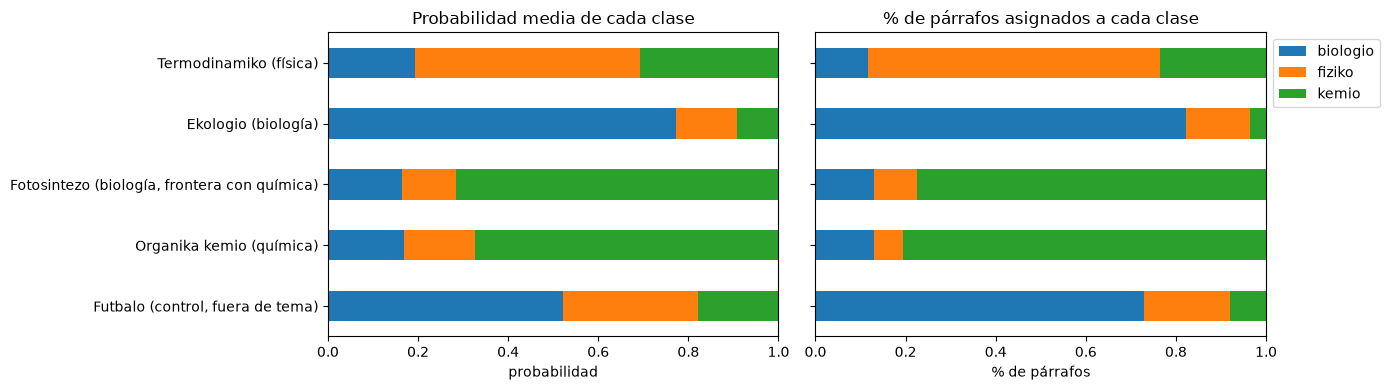

In [27]:
if tablas:
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4), sharey=True)

    resultados[CLASES].plot.barh(stacked=True, ax=ax1, legend=False)
    ax1.set(title="Probabilidad media de cada clase", xlabel="probabilidad", ylabel="", xlim=(0, 1))

    reparto = pd.crosstab(detalle["página"], detalle["predicción"], normalize="index")
    reparto = reparto.reindex(index=resultados.index, columns=CLASES, fill_value=0)
    reparto.plot.barh(stacked=True, ax=ax2)
    ax2.set(title="% de párrafos asignados a cada clase", xlabel="% de párrafos", xlim=(0, 1))
    ax2.legend(bbox_to_anchor=(1, 1))

    ax1.invert_yaxis()
    plt.tight_layout()
    plt.show()

Para ver de dónde salen esas medias, estos son los párrafos de cada página en los que el modelo **duda más**
(la clase más probable tiene menos probabilidad):

In [28]:
if tablas:
    detalle["confianza"] = detalle[CLASES].max(axis=1)
    for nombre in resultados.index:
        print(f"--- {nombre} ---")
        dudosos = detalle[detalle["página"] == nombre].nsmallest(2, "confianza")
        display(dudosos[CLASES + ["predicción", "texto"]].round(2))

--- Termodinamiko (física) ---


,biologio,fiziko,kemio,predicción,texto
11,0.38,0.32,0.30,biologio,"En 1849, la anglalingva adjekto thermo-dynamic (termodinamika) estis uzita de William Thomson. En 1854, la anglalingva substantivo thermo-dynamics (termodinamiko) estis uzata de Thomson kaj William Rankine por reprez..."
13,0.27,0.39,0.34,fiziko,"La studo de termodinamikaj sistemoj evoluis modelon en rilataj branĉoj, ĉiu utiligante malsaman fundamentan kiel teorian aŭ eksperimentan bazon, aŭ aplikante la principojn al ŝanĝiĝantaj specoj de sistemoj."


--- Ekologio (biología) ---


,biologio,fiziko,kemio,predicción,texto
41,0.42,0.45,0.13,fiziko,"La skalo de ekologia dinamiko povas funkcii kiel fermata sistemo, kiel afidoj migrantaj sur unusola arbo, dum samtempe restas malfermaj kun rilato al influoj de pli larĝaj skaloj, kiel atmosfero aŭ klimato. Tiel, eko..."
59,0.44,0.47,0.09,fiziko,"Plantekologio estas subfako de ekologio kiu studas la distribuadon kaj abundon de plantoj, la efikoj de la mediaj faktoroj sur la abundo de plantoj kaj la interagado inter plantoj kaj aliaj organismoj. Ties ekzemploj..."


--- Fotosintezo (biología, frontera con química) ---


,biologio,fiziko,kemio,predicción,texto
64,0.42,0.20,0.38,biologio,"La organoj de la fotosintezo estas la verdaj kloroplastoj. En verdaj plantoj kaj algoj, la pigment molekuloj, kiuj komence akceptas la lumenergion, estas klorofiloj kun helpantaj pigmentoj kiel karotinoidoj, fikobili..."
75,0.16,0.44,0.40,fiziko,"En la sama linio de la menciitaj aŭtoroj, Jean Senebier, el Ĝenevo, plenumas novajn eksperimentojn kiuj establas la neceson de la lumo por ke okazu la asimiladon de la karbona dioksido kaj la forigon de oksigeno. Li ..."


--- Organika kemio (química) ---


,biologio,fiziko,kemio,predicción,texto
100,0.37,0.20,0.43,kemio,Fruaj ekzemploj de organikaj reakcioj kaj aplikoj estis ofte trovitaj pro kombino de sorto kaj preparado por neatenditaj observoj. La lasta duono de la 19a jarcento tamen estis atestanto de sistemaj studoj de organik...
101,0.33,0.23,0.44,kemio,"La mult-ŝtupa sintezo de kompleksaj organikaj komponaĵoj estas nomata ""totala sintezo"". Totala sintezo de kompleksaj naturaj komponaĵoj pliiĝis laŭ komplekseco ĝis glukozo kaj terpineolo. Por ekzemplo, kolesterolo -r..."


--- Futbalo (control, fuera de tema) ---


,biologio,fiziko,kemio,predicción,texto
151,0.4,0.22,0.38,biologio,"Mezulo, mezkampisto, mezkampulo aŭ mezludisto, estas la futbalisto ĉu atakanta ĉu defendanta kiu ludas ĉefe en la centro de la ludejo. Ties ĉefaj funkcioj estas la jenaj: ekvilibrigi la teamon inter la defendo kaj la..."
139,0.4,0.28,0.32,biologio,"La pilko estu ronda kaj el taŭga materialo, kiel ekzemple ledo. La ludado estas regata de arbitraciisto, kiu estas helpata de du subarbitraciistoj kiuj kuras laŭlonge de la flankaj linioj. Lastatempe en diversaj kate..."


### 5.5 Análisis de los resultados web

- **Ekologio** (≈ 77 % biología), **Organika kemio** (≈ 67 % química) y **Termodinamiko** (≈ 50 % física) se
  clasifican bien. La termodinámica tiene bastante probabilidad de química (≈ 30 %), y tiene sentido: habla de calor,
  energía, presión y gases, que también son conceptos de química física.
- **Fotosintezo** sale como **química** (≈ 72 %). No es un error absurdo: el artículo explica la fotosíntesis a nivel
  molecular (CO₂, glucosa, clorofila, oxidación...), que es **bioquímica**. Es justo el tipo de texto de frontera que
  hace que las temáticas sean cercanas. Los párrafos más "biológicos" (los cloroplastos, las plantas) sí reparten la
  probabilidad hacia biología.
- La página de **fútbol** sale como biología, pero con una probabilidad baja (≈ 52 %) y repartida. El modelo
  **siempre** elige una de las tres clases que conoce, aunque el texto no sea de ninguna; el vocabulario sobre personas
  y su cuerpo se parece más al de biología. Para detectar textos fuera de tema haría falta una cuarta clase "otros" en
  el dataset, o rechazar las páginas cuya probabilidad máxima no supere un umbral.
- La **web caída** no detiene el cuaderno: se avisa del error y se sigue con el resto de páginas.
- Los **párrafos dudosos** suelen ser de historia o de introducción (fechas, nombres de científicos...), que no son
  propios de ningún tema: es el mismo tipo de ruido que tiene el dataset.

## 6. Conclusiones

### Resultados

- **Dataset:** unos 1100 párrafos de la Wikipedia en esperanto, equilibrados entre `fiziko`, `biologio` y `kemio`, que
  cumplen el contrato de datos. Las tres temáticas comparten mucho vocabulario científico, así que el problema no es
  trivial.
- **Librería `ciencianlp`:** procesa todo el corpus en menos de un segundo y solo deja sin etiquetar (`X`) en torno
  al 3 % de los tokens. Usarla para lematizar y filtrar por stop-words y POS **mejora el F1 macro unos 5 puntos**
  frente a usar las palabras tal cual. Es la mejor prueba de que la librería es útil.
- **Modelo:** TF-IDF hecho a mano (como en el ejercicio 06) y regresión logística, elegida entre los cuatro modelos
  vistos en clase con validación cruzada. En test obtiene **≈ 0.86 de accuracy y de F1 macro**, con errores
  repartidos entre las tres clases.
- **Páginas web:** las páginas claramente de un tema se clasifican bien. Las de frontera (fotosíntesis →
  bioquímica, termodinámica → física y química) reparten la probabilidad, y la de fútbol demuestra que el modelo no sabe
  decir "ninguna de las tres".

### El ruido del dataset

Cada párrafo hereda la etiqueta de su artículo, y no todos hablan del tema (biografías, historia, aplicaciones
técnicas, temas de frontera...). Con el script `scripts/medir_ruido.py` (explicado en el README) estimamos que **como
mucho un 22 % de los párrafos** son posible ruido. Muchos de los "errores" más seguros del modelo son en realidad
estos párrafos, así que el ruido marca el techo de rendimiento más que el algoritmo.

### Limitaciones y mejoras

- **Dataset:** filtrar los párrafos sin lemas distintivos al construirlo y eliminar las referencias bibliográficas que
  aún se cuelan. También se podrían usar más subcategorías de Wikipedia para tener más datos.
- **Librería:** normalizar la grafía antigua (*ĥemio* → *kemio*) y usar el contexto en el POS-tagger (ahora etiqueta
  cada palabra por separado). También se podrían separar las palabras compuestas en sus raíces (*fotosintezo* →
  *foto* + *sintezo*), aprovechando que el esperanto es aglutinante.
- **Modelo:** para textos fuera de tema haría falta una clase "otros" o un umbral de rechazo.
- **Independencia de temática:** el cuaderno lee las clases del dataset, así que cambiando `URL_DATASET` (y la lista
  `PAGINAS`) se reentrena y evalúa con el dataset de cualquier otro equipo que cumpla el contrato.